# 14. Global optimization of noisy expected improvement

In active learning with real experiments, every measurement is noisy. Expected
improvement (EI) needs the best value seen so far, $f^*$, and with noise that
value is not known: the smallest *observed* $y$ is usually a lucky draw, lower
than the function there. Using it as $f^*$ makes EI too pessimistic about
everywhere else, so the search keeps resampling near the lucky point.

Noisy expected improvement (NEI), from Letham, Karrer, Ottoni and Bakshy
[letham2019constrained], integrates over that uncertainty instead. The GP posterior gives a joint distribution of the noise-free values
$f(X) = (f(x_1), \dots, f(x_N))$ at the data. For one sample $f_m$ of it the
best value is known, $f^*_m = \min_i f_{m,i}$, and EI is computed for a
noise-free GP conditioned on $f_m$. NEI is the average:

$$ \mathrm{NEI}(x) = \mathbb E_{f(X)\mid D}\big[\mathrm{EI}(x \mid f(X))\big]
   \approx \frac1M \sum_{m=1}^M \mathrm{EI}\big(\mu_m(x),\ \sigma_0(x),\ f^*_m\big), $$

where, with $K_0 = K_{X,X}$ the noise-free training covariance,

$$ \mu_m(x) = k_{x,X} K_0^{-1} f_m, \qquad
   \sigma_0(x)^2 = \sigma_f^2 - k_{x,X} K_0^{-1} k_{X,x}. $$

The samples $f_m$ are drawn once, with scrambled Sobol (quasi-Monte Carlo)
points pushed through the normal quantile, and then held fixed, as in the
paper. So the approximation is a deterministic function of $x$: a sum of $M$
EI terms that share one standard deviation $\sigma_0$ and differ in their
mean. Each term is multimodal (near zero at the data, with a bump between
points) and so is the sum, which is the case for solving it globally.

For jaxglobal this is an ordinary JAX function built from the primitives of
`jaxglobal.gp` (see notebook 06): $M$ calls to `gp_mean` (one weight vector
$K_0^{-1} f_m$ each), one `gp_std`, and $M$ calls to `expected_improvement`.
Each is relaxed with its own structure, so the sum is certified like EI is.

This notebook:

1. builds NEI in 1-D and compares it with EI computed from the noisy best
   observation and from the best posterior mean;
2. maximizes NEI globally in 2-D, checks the certificate on a grid, and
   compares it with the multistart local search that Bayesian-optimization
   libraries use for this step;
3. runs an active-learning loop on a noisy 2-D function with a certified
   NEI step at every iteration, against EI with the noisy incumbent.

In [1]:
import os
import pathlib
import sys
import time

os.environ.setdefault("RUST_LOG", "warn")  # keep the local NLP solver's info messages out of the output
ROOT = pathlib.Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize as sp_minimize
from scipy.stats import norm, qmc

import jaxglobal.bnb
from jaxglobal import minimize
from jaxglobal.gp import expected_improvement, gp_mean, gp_std

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})
TOL = dict(abs_tol=1e-3, rel_tol=1e-3)

## A GP with known noise, and its NEI

The GP is the one from notebook 06 (Matérn 5/2, inputs scaled to $[-1,1]$,
outputs standardized, hyperparameters by maximum marginal likelihood), with
one change: the noise variance is given, not fitted. With 10 to 20 points
the likelihood often cannot tell noise from signal and fits a nearly
interpolating GP, which leaves nothing for NEI to integrate over. In an
experimental campaign the noise level usually comes from replicates.

`nei` returns $-\mathrm{NEI}$ as a function for `minimize`. The noise-free
$K_0$ gets a jitter of $10^{-6}$ (in standardized units) so that it can be
inverted; the fantasies $f_m$ come from the noisy GP's posterior at the data,

$$ f(X)\mid D \sim \mathcal N\!\big(K_0 K^{-1} y,\ K_0 - K_0 K^{-1} K_0\big),
   \qquad K = K_0 + \sigma_n^2 I. $$

In [2]:
def m52(d):  # Matérn 5/2 as a function of the squared scaled distance (training only)
    return (1 + jnp.sqrt(5 * d) + 5 * d / 3) * jnp.exp(-jnp.sqrt(5 * d))


class NoisyGP:
    """Matérn 5/2 GP with a known noise standard deviation, and its acquisition functions."""

    def __init__(self, X, y, lo, hi, noise_sd, seed=0, jitter=1e-6):
        self.lo, self.hi = np.asarray(lo, float), np.asarray(hi, float)
        X, y = np.atleast_2d(np.asarray(X, float)), np.asarray(y, float)
        self.Xs = Xs = self.scale(X)
        self.ym, self.ys = float(y.mean()), float(y.std())
        yt = (y - self.ym) / self.ys
        n, dim = Xs.shape
        sn2 = (noise_sd / self.ys) ** 2  # fixed noise variance, standardized units

        def gram0(th):  # noise-free covariance
            lam, sf2 = jnp.exp(th[:dim]), jnp.exp(th[dim])
            d = (((Xs[:, None, :] - Xs[None, :, :]) / lam) ** 2).sum(-1)
            return sf2 * m52(d + 1e-30)  # 1e-30 keeps d/dd sqrt(d) finite on the diagonal

        def nll(th):
            L = jnp.linalg.cholesky(gram0(th) + (sn2 + 1e-8) * jnp.eye(n))
            a = jax.scipy.linalg.cho_solve((L, True), yt)
            return 0.5 * yt @ a + jnp.log(jnp.diag(L)).sum()

        vg = jax.jit(jax.value_and_grad(nll))
        bounds = [(-4.0, 2.0)] * dim + [(-3.0, 3.0)]
        rng = np.random.default_rng(seed)
        best = None
        for _ in range(10):
            r = sp_minimize(lambda t: [np.asarray(v, float) for v in vg(t)], [rng.uniform(a, b) for a, b in bounds],
                            jac=True, method="L-BFGS-B", bounds=bounds)
            if np.isfinite(r.fun) and (best is None or r.fun < best.fun):
                best = r
        th = best.x
        self.lam, self.sf2, self.sn2 = np.exp(th[:dim]), float(np.exp(th[dim])), sn2
        K0 = np.asarray(gram0(th))
        K = K0 + (sn2 + 1e-8) * np.eye(n)
        self.alpha, self.Kinv = np.linalg.solve(K, yt), np.linalg.inv(K)  # noisy GP
        self.K0inv = np.linalg.inv(K0 + jitter * np.eye(n))  # noise-free GP of the fantasies
        self.f_mean = K0 @ self.alpha  # posterior of f at the data (standardized)
        self.f_cov = K0 - K0 @ self.Kinv @ K0

    def scale(self, x):
        return 2 * (x - self.lo) / (self.hi - self.lo) - 1

    # the noisy GP: posterior of f(x)
    def mean(self, x):
        return self.ym + self.ys * gp_mean(self.scale(x), self.Xs, self.lam, self.alpha, self.sf2)

    def std(self, x):
        return self.ys * gp_std(self.scale(x), self.Xs, self.lam, self.Kinv, self.sf2)

    def fantasies(self, m, seed=0):
        """M quasi-random samples of f(X) | D, standardized, shape (M, N)."""
        n = len(self.Xs)
        u = qmc.Sobol(n, scramble=True, seed=seed).random(m)
        L = np.linalg.cholesky(self.f_cov + 1e-10 * np.eye(n))
        return self.f_mean + norm.ppf(u) @ L.T

    def nei(self, m=8, seed=0):
        """-NEI(x) with M fixed QMC fantasies (in the units of y)."""
        F = self.fantasies(m, seed)
        A = F @ self.K0inv.T  # weights of each fantasy's noise-free GP mean
        fstar = F.min(axis=1)  # each fantasy's best value
        Xs, lam, sf2, K0inv, ys = self.Xs, self.lam, self.sf2, self.K0inv, self.ys

        def neg_nei(x):
            u = self.scale(x)
            s0 = gp_std(u, Xs, lam, K0inv, sf2)
            ei = sum(expected_improvement(gp_mean(u, Xs, lam, a, sf2), s0, b) for a, b in zip(A, fstar))
            return -ys * ei / m

        return neg_nei

    def ei(self, fstar):
        """-EI(x) of the noisy GP below a given incumbent value fstar."""
        return lambda x: -expected_improvement(self.mean(x), self.std(x), fstar)


def solve(f, lo, hi, **kw):
    t = time.perf_counter()
    r = minimize(f, lo, hi, **TOL, **kw)
    t = time.perf_counter() - t
    # every acquisition function here is a new problem that is solved once: drop its compiled
    # kernels (jaxglobal keeps the last 32 problems in memory), or a long loop runs out of memory
    jaxglobal.bnb.clear_cache()
    jax.clear_caches()
    return r, t

## 1. What NEI does, in 1-D

The function is $f(x) = \sin x + \sin(10x/3)$ on $[2.7, 7.5]$, with global
minimum $-1.8996$ at $x = 5.1457$ and a second minimum $-1.60$ near
$x = 3.0$. Eight noisy measurements, noise standard deviation 0.3. Three
acquisition functions, each certified with `minimize`:

* **EI, noisy incumbent**: EI of the noisy GP below $\min_i y_i$;
* **EI, mean incumbent**: EI below $\min_i \mu(x_i)$, a common fix;
* **NEI** with $M = 16$ fantasies.

In [3]:
def f1(x):
    return jnp.sin(x[..., 0]) + jnp.sin(10 * x[..., 0] / 3)


LO1, HI1, SD1 = np.array([2.7]), np.array([7.5]), 0.3
rng = np.random.default_rng(4)
X1 = qmc.scale(qmc.LatinHypercube(d=1, seed=2).random(8), LO1, HI1)
y1 = np.asarray(f1(X1)) + SD1 * rng.normal(size=len(X1))
gp1 = NoisyGP(X1, y1, LO1, HI1, noise_sd=SD1)
mu_data = np.asarray(jax.vmap(gp1.mean)(jnp.array(X1)))
print(f"best observed y = {y1.min():.3f} at x = {X1[y1.argmin(), 0]:.3f} (f there: {float(f1(X1[y1.argmin()])):.3f}); "
      f"best posterior mean at the data = {mu_data.min():.3f}")

acq1 = {"EI, noisy incumbent": gp1.ei(float(y1.min())),
        "EI, mean incumbent": gp1.ei(float(mu_data.min())),
        "NEI (M = 16)": gp1.nei(16)}
xg = np.linspace(LO1[0], HI1[0], 2001)[:, None]
rows, picks = [], {}
for name, f in acq1.items():
    r, t = solve(f, LO1, HI1)
    vals = np.asarray(jax.jit(jax.vmap(f))(jnp.array(xg)))
    picks[name] = (r, vals)
    rows.append(dict(acquisition=name, status=r.status, x_next=r.x[0], value=-r.fun, proven_max=-r.lower_bound,
                     grid_max=-vals.min(), nodes=r.nodes, time_s=t))
pd.DataFrame(rows)

best observed y = -1.234 at x = 5.543 (f there: -1.039); best posterior mean at the data = -1.024


,acquisition,status,x_next,value,proven_max,grid_max,nodes,time_s
0,"EI, noisy incumbent",optimal,5.446777,0.040873,0.041864,0.040871,45,2.076412
1,"EI, mean incumbent",optimal,5.514426,0.106102,0.106832,0.106101,33,1.876122
2,NEI (M = 16),optimal,5.418894,0.066307,0.067166,0.066307,55,10.612483


All three maxima are certified, and each proven upper bound is at or above
the maximum on a 2001-point grid. The plot shows why they differ. The
fantasies (thin lines, top) are the noise-free functions consistent with the
data; each has its own minimum, and NEI averages the EI of each one.

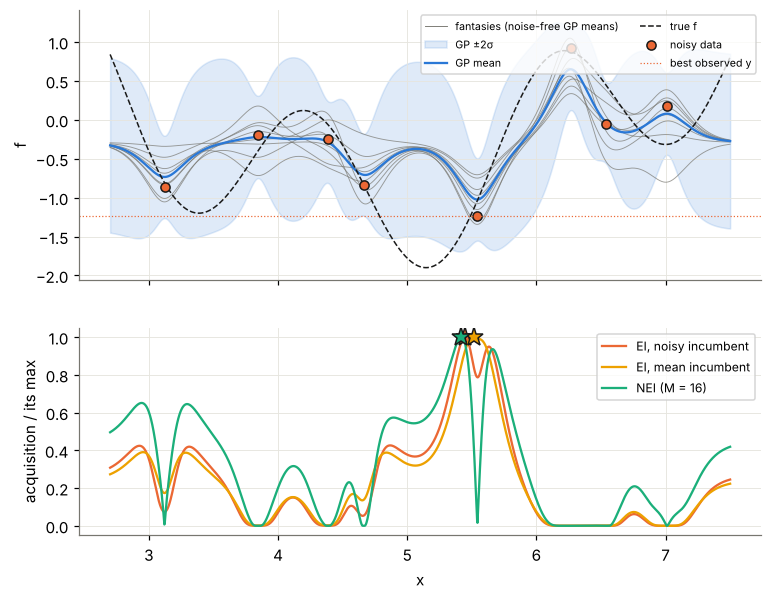

In [4]:
F1 = gp1.fantasies(16)
mu_g = np.asarray(jax.vmap(gp1.mean)(jnp.array(xg)))
sd_g = np.asarray(jax.vmap(gp1.std)(jnp.array(xg)))
fig, axes = plt.subplots(2, 1, figsize=(8, 6.2), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1]))
ax = axes[0]
for a in F1[:8] @ gp1.K0inv.T:  # a few fantasies' noise-free means
    fm = gp1.ym + gp1.ys * np.asarray(jax.vmap(lambda x: gp_mean(gp1.scale(x), gp1.Xs, gp1.lam, a, gp1.sf2))(jnp.array(xg)))
    ax.plot(xg, fm, color=MUTED, lw=0.6, alpha=0.7)
ax.plot([], [], color=MUTED, lw=0.6, label="fantasies (noise-free GP means)")
ax.fill_between(xg[:, 0], mu_g - 2 * sd_g, mu_g + 2 * sd_g, color=BLUE, alpha=0.15, label="GP ±2σ")
ax.plot(xg, mu_g, color=BLUE, label="GP mean")
ax.plot(xg, np.asarray(f1(jnp.array(xg))), "--", color=INK, lw=1, label="true f")
ax.plot(X1, y1, "o", color=ORANGE, mec=INK, label="noisy data")
ax.axhline(y1.min(), color=ORANGE, lw=0.8, ls=":", label="best observed y")
ax.legend(fontsize=7, ncol=2, loc="upper right")
ax.set_ylabel("f")
ax = axes[1]
for (name, (r, vals)), col in zip(picks.items(), (ORANGE, YELLOW, AQUA)):
    v = -vals / (-vals).max()
    ax.plot(xg, v, color=col, label=name)
    ax.plot(r.x, [1.0], "*", color=col, mec=INK, ms=13)
ax.set_ylabel("acquisition / its max")
ax.set_xlabel("x")
ax.legend(fontsize=8)
plt.show()

With these data the best observation is a lucky draw: $y = -1.23$ at
$x = 5.54$, where $f = -1.04$ and the GP mean is $-1.02$. The three
acquisition functions agree on *where* to look next (all pick
$x \approx 5.42$ to $5.51$, between that point and the true minimum at
5.15) but not on how much there is to gain. EI below the lucky $y$ is the
most pessimistic (0.041); EI below the best posterior mean is the most
optimistic (0.106), because it treats that mean as the exact best value;
NEI is in between (0.066), because in each fantasy the best value, and
sometimes the best point, is different. In a loop these magnitudes matter:
they decide how exploration and exploitation are traded off at the next
step, and when a stopping rule based on the acquisition value fires.

### How many fantasies?

The QMC estimate converges quickly, but every fantasy adds a `gp_mean` and
an EI term to the function, so the solve time grows about linearly in $M$.
Below, the certified maximizer for several $M$ (and two Sobol seeds):

In [5]:
rows = []
for m in (4, 8, 16):
    for seed in (0, 1):
        r, t = solve(gp1.nei(m, seed=seed), LO1, HI1)
        rows.append(dict(M=m, seed=seed, status=r.status, x_next=r.x[0], NEI=-r.fun, nodes=r.nodes, time_s=t))
pd.DataFrame(rows)

,M,seed,status,x_next,NEI,nodes,time_s
0,4,0,optimal,5.424862,0.068389,55,3.530179
1,4,1,optimal,5.435438,0.051371,57,3.480468
2,8,0,optimal,5.421558,0.069087,55,10.527966
3,8,1,optimal,5.429204,0.063702,53,5.712265
4,16,0,optimal,5.418894,0.066307,55,10.452811
5,16,1,optimal,5.424451,0.068360,55,12.013253


Each row is a certified maximum of its own (deterministic) approximation.
The maximizer moves by less than 0.02 between $M = 4$ and $M = 16$, and the
NEI value by about 0.02 at $M = 4$ and 0.002 at $M = 16$ between the two
seeds. $M = 8$ is what the loop below uses. The function is unrolled into $M$
`gp_mean` and EI terms, and the compile time grows faster than linearly:
at $M = 32$ the XLA compile alone took more than 10 minutes on this
machine, so the sweep stops at 16.

## 2. One NEI step in 2-D: certificate and multistart

The 2-D problem is the peaks function of notebook 06 on $[-3,3]^2$ (minimum
$-6.551$ at $(0.228, -1.626)$), measured with noise standard deviation 0.5,
from a 15-point Latin hypercube. $-\mathrm{NEI}$ with $M = 8$ is minimized
with `minimize` and checked on a $301\times301$ grid.

In [6]:
def peaks(x):
    x1, x2 = x[..., 0], x[..., 1]
    return (3 * (1 - x1) ** 2 * jnp.exp(-x1**2 - (x2 + 1) ** 2)
            - 10 * (x1 / 5 - x1**3 - x2**5) * jnp.exp(-x1**2 - x2**2)
            - jnp.exp(-(x1 + 1) ** 2 - x2**2) / 3)


LO, HI, SD, M = np.array([-3.0, -3.0]), np.array([3.0, 3.0]), 0.5, 8
XSTAR, FSTAR = np.array([0.228, -1.626]), -6.551
g = np.linspace(-3, 3, 301)
GRID = jnp.array(np.stack(np.meshgrid(g, g), -1).reshape(-1, 2))


def lhs(n, seed):
    return qmc.scale(qmc.LatinHypercube(d=2, seed=seed).random(n), LO, HI)


rng = np.random.default_rng(1)
X2 = lhs(15, seed=0)
y2 = np.asarray(peaks(X2)) + SD * rng.normal(size=len(X2))
gp2 = NoisyGP(X2, y2, LO, HI, noise_sd=SD)
neg_nei2 = gp2.nei(M)
r2, t2 = solve(neg_nei2, LO, HI, time_limit=300)
nei_grid = np.asarray(jax.jit(jax.vmap(neg_nei2))(GRID))
print(r2)
print(f"{t2:.1f} s; grid maximum of NEI {-nei_grid.min():.5f} at {np.asarray(GRID[nei_grid.argmin()])}; "
      f"proven maximum <= {-r2.lower_bound:.5f}")

Result(status='optimal', fun=-0.4144815, lower_bound=-0.4154775, gap=9.96e-04, x=[-2.025198  0.129988], nodes=539, iterations=17, time=5.79s)
5.8 s; grid maximum of NEI 0.41444 at [-2.02  0.12]; proven maximum <= 0.41548


The certificate brackets the grid maximum. The usual way to do this step is
a multistart local search: L-BFGS-B from random points, keep the best. Here
it is with exact gradients from JAX, repeated 100 times for each number of
starts, counted as a success if it gets within the solver's tolerance of the
certified value.

In [7]:
nei_vg = jax.jit(jax.value_and_grad(neg_nei2))


def multistart(k, rng):
    best = np.inf
    for x0 in rng.uniform(LO, HI, size=(k, 2)):
        r = sp_minimize(lambda x: [np.asarray(v, float) for v in nei_vg(x)], x0, jac=True, method="L-BFGS-B",
                        bounds=list(zip(LO, HI)))
        best = min(best, r.fun)
    return best


rng = np.random.default_rng(0)
tol = TOL["abs_tol"] + TOL["rel_tol"] * abs(r2.fun)
rows = []
for k in (1, 2, 5, 10, 20):
    t = time.perf_counter()
    found = np.array([multistart(k, rng) for _ in range(100)])
    rows.append(dict(starts=k, found_global=np.mean(found <= r2.fun + tol), worst_NEI=-found.max(),
                     median_NEI=-np.median(found), time_per_run_s=(time.perf_counter() - t) / 100))
pd.DataFrame(rows)

,starts,found_global,worst_NEI,median_NEI,time_per_run_s
0,1,0.31,0.000000e+00,0.086282,0.005360
1,2,0.70,5.334511e-11,0.414482,0.007736
2,5,0.97,7.323522e-02,0.414482,0.017830
3,10,1.00,4.144815e-01,0.414482,0.032220
4,20,1.00,4.144815e-01,0.414482,0.062840


One start finds the global maximum in 31 of 100 runs, two starts in 70,
five in 97, and ten or more in all of them here. A run that misses can return
a much smaller value (with one start, as low as 0: a flat region where NEI
is zero to machine precision), and nothing in the result says that it
missed. Multistart is much faster than branch and bound (milliseconds against
a minute), so in practice it is the right tool for the loop; the certified
solve tells you how many starts were enough on a problem like this one. The branch-and-bound result
comes with a proven upper bound, so there is no question of how many starts
were enough.

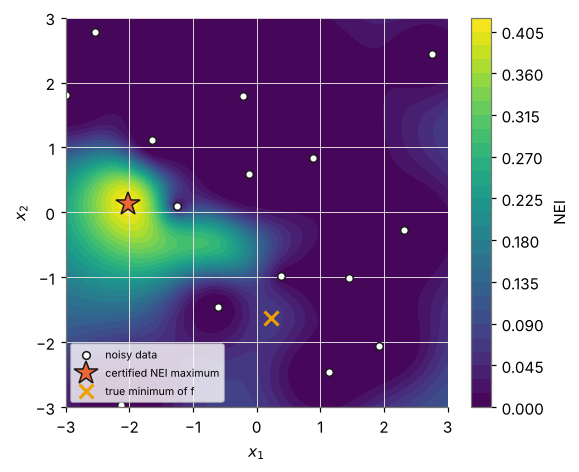

In [8]:
fig, ax = plt.subplots(figsize=(5.6, 4.6))
cs = ax.contourf(g, g, -nei_grid.reshape(301, 301), levels=30, cmap="viridis")
fig.colorbar(cs, ax=ax, label="NEI")
ax.plot(*X2.T, "o", color="white", mec=INK, ms=5, label="noisy data")
ax.plot(*r2.x, "*", color=ORANGE, mec=INK, ms=16, label="certified NEI maximum")
ax.plot(*XSTAR, "x", color=YELLOW, mew=2, ms=9, label="true minimum of f")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend(fontsize=7, loc="lower left")
plt.show()

## 3. Active learning on noisy peaks

Now the loop. Start from 10 noisy points, then at each of 10 iterations
refit the GP, add the point that maximizes the acquisition function
(certified, at most 120 s per step) and measure it with noise. Two
strategies from the same start:

* **NEI**, $M = 8$;
* **EI with the noisy incumbent** $\min_i y_i$, the naive choice.

With noise, "best observed $y$" is not a good report either. After each
step, each strategy recommends the data point with the lowest GP mean, and
we record the *true* $f$ there: the quality of what an experimenter would
take away.

In [9]:
X0 = lhs(10, seed=3)
y0 = np.asarray(peaks(X0)) + SD * np.random.default_rng(3).normal(size=len(X0))
STEPS = 10


def run(strategy, seed=7):
    noise = np.random.default_rng(seed)  # same noise sequence for both strategies
    X, y, log = X0.copy(), y0.copy(), []
    for it in range(STEPS + 1):
        gp = NoisyGP(X, y, LO, HI, noise_sd=SD)
        mu = np.asarray(jax.vmap(gp.mean)(jnp.array(X)))
        rec = X[mu.argmin()]
        entry = dict(iteration=it, N=len(y), recommended_f=float(peaks(rec)), best_y=float(y.min()),
                     dist_to_opt=float(np.linalg.norm(rec - XSTAR)))
        if it == STEPS:
            log.append(entry)
            break
        f = gp.nei(M) if strategy == "NEI" else gp.ei(float(y.min()))
        r, t = solve(f, LO, HI, time_limit=120)
        ynew = float(peaks(r.x)) + SD * noise.normal()
        log.append(entry | dict(status=r.status, acq=-r.fun, acq_bound=-r.lower_bound, x1=r.x[0], x2=r.x[1],
                                y_new=ynew, time_s=t))
        X, y = np.vstack([X, r.x]), np.append(y, ynew)
    return pd.DataFrame(log), X


runs = {}
for strategy in ("NEI", "EI (noisy incumbent)"):
    runs[strategy] = run(strategy)
runs["NEI"][0]

,iteration,N,recommended_f,best_y,dist_to_opt,status,acq,acq_bound,x1,x2,y_new,time_s
0,0,10,-2.487701,-2.771585,0.760025,optimal,0.207593,0.208418,1.475826,-1.163123,0.306784,6.968877
1,1,11,-2.487701,-2.771585,0.760025,optimal,0.181685,0.182682,1.031624,-3.000000,0.046314,6.754639
2,2,12,-2.487701,-2.771585,0.760025,optimal,0.191657,0.192641,0.695015,-1.601862,-4.925288,6.895424
3,3,13,-4.788219,-4.925288,0.467639,optimal,0.213916,0.214891,0.542355,-1.810854,-5.653837,6.097841
4,4,14,-5.208541,-5.653837,0.364678,optimal,0.199364,0.200238,0.344483,-2.008002,-4.960795,7.245241
5,5,15,-5.208541,-5.653837,0.364678,optimal,0.108667,0.109650,0.667945,-1.972710,-4.296127,6.415592
6,6,16,-5.208541,-5.653837,0.364678,optimal,0.203297,0.204234,0.481640,-1.477207,-5.743030,6.852765
7,7,17,-5.773102,-5.743030,0.294062,optimal,0.062254,0.063250,0.505714,-1.144824,-2.830652,6.956212
8,8,18,-5.208541,-5.743030,0.364678,optimal,0.310018,0.310740,0.334537,-1.675777,-6.639549,7.124565
9,9,19,-6.393446,-6.639549,0.117592,optimal,0.169625,0.170608,0.049563,-1.720345,-6.504611,6.384482


In [10]:
runs["EI (noisy incumbent)"][0]

,iteration,N,recommended_f,best_y,dist_to_opt,status,acq,acq_bound,x1,x2,y_new,time_s
0,0,10,-2.487701,-2.771585,0.760025,optimal,0.224920,0.225916,1.425061,-1.174023,0.194594,2.642077
1,1,11,-2.487701,-2.771585,0.760025,optimal,0.213890,0.214882,1.013079,-2.999998,0.042290,2.290531
2,2,12,-2.487701,-2.771585,0.760025,optimal,0.223700,0.224673,0.704435,-1.519812,-4.792079,2.064909
3,3,13,-4.655010,-4.792079,0.488126,optimal,0.200497,0.201488,0.579567,-1.715425,-5.787335,2.111607
4,4,14,-5.342039,-5.787335,0.362762,optimal,0.172315,0.173315,0.430533,-1.908344,-5.386010,1.997514
5,5,15,-5.342039,-5.787335,0.362762,optimal,0.108790,0.109725,0.679345,-1.908097,-4.563665,2.404485
6,6,16,-5.342039,-5.787335,0.362762,optimal,0.124657,0.125644,0.456672,-1.441088,-5.702788,1.973063
7,7,17,-5.732860,-5.787335,0.294080,optimal,0.086270,0.087232,0.472862,-1.492375,-5.184347,2.946926
8,8,18,-5.854454,-5.787335,0.278950,optimal,0.080634,0.081523,0.103908,-3.000000,-0.499157,2.853319
9,9,19,-5.854454,-5.787335,0.278950,optimal,0.067563,0.068367,3.000000,-3.000000,-0.310243,2.148638


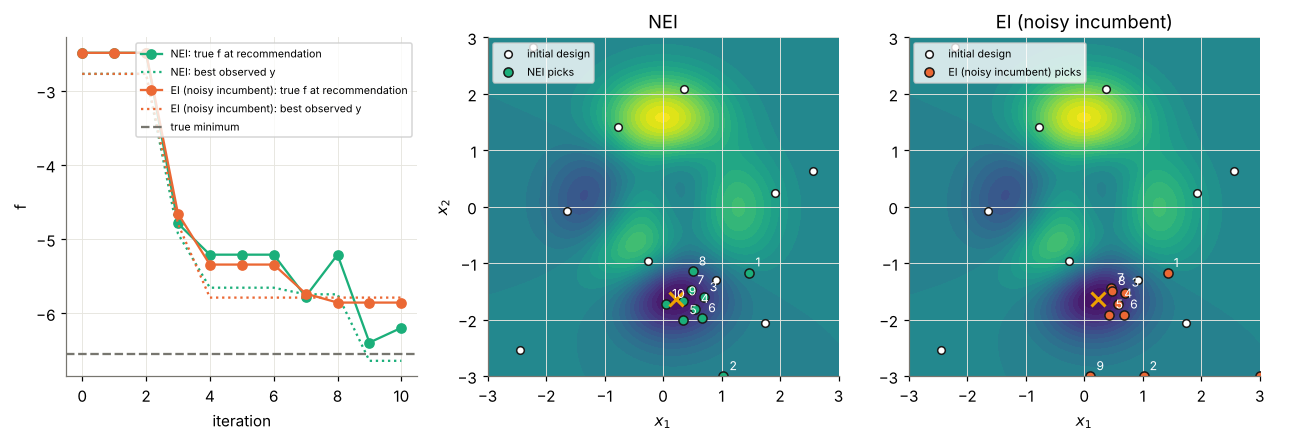

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ax = axes[0]
for (name, (log, _)), col in zip(runs.items(), (AQUA, ORANGE)):
    ax.plot(log.iteration, log.recommended_f, "o-", color=col, label=f"{name}: true f at recommendation")
    ax.plot(log.iteration, log.best_y, ":", color=col, label=f"{name}: best observed y")
ax.axhline(FSTAR, color=MUTED, ls="--", label="true minimum")
ax.set_xlabel("iteration")
ax.set_ylabel("f")
ax.legend(fontsize=7)
G2 = jnp.array(np.stack(np.meshgrid(g, g), -1))
for ax, (name, (log, X)), col in zip(axes[1:], runs.items(), (AQUA, ORANGE)):
    ax.contourf(g, g, np.asarray(peaks(G2)), levels=30, cmap="viridis")
    ax.plot(*X0.T, "o", color="white", mec=INK, ms=5, label="initial design")
    ax.plot(*X[len(X0):].T, "o", color=col, mec=INK, ms=6, label=f"{name} picks")
    for i, p in enumerate(X[len(X0):]):
        ax.annotate(str(i + 1), p, xytext=(4, 4), textcoords="offset points", color="white", fontsize=8)
    ax.plot(*XSTAR, "x", color=YELLOW, mew=2, ms=9)
    ax.set_title(name)
    ax.set_xlabel("$x_1$")
    ax.legend(fontsize=7, loc="upper left")
axes[1].set_ylabel("$x_2$")
plt.show()

Every acquisition step in both loops ends with a certificate (`status`,
and `acq_bound` within the tolerance of `acq`). A NEI step took about 55 s
and an EI step 17 s on the first run on a 4-core VM, almost all of it
compiling; with jaxglobal's on-disk kernel cache filled by that run, the
stored outputs show about 7 s and 2 s. So the difference between the two runs comes from the
acquisition functions, not from how well each was optimized; with
multistart a poor step could be either.

Both strategies find the valley of the global minimum by iteration 3. After
10 steps, NEI's recommendation has true $f = -6.19$, 0.20 from the true
minimizer, and EI's has $-5.85$, 0.28 away. In its last two steps EI with
the noisy incumbent spends its measurements on the boundary
($x_2 = -3$, and the corner $(3, -3)$): its incumbent $-5.79$ is a lucky draw
below the GP mean, so improving on it looks unlikely near the data and EI
turns to the least-known regions. NEI keeps refining the valley. This is one
run with one noise sequence, an illustration rather than a benchmark.

Note the dotted lines: the best *observed* $y$ goes below the true
minimum of $-6.55$ as soon as a point near it is measured, because of noise.
This is the bias that the noisy incumbent feeds into EI.

## Summary

* NEI is a sum of $M$ expected-improvement terms over noise-free "fantasy"
  GPs, with fixed QMC samples. Written with `gp_mean`, `gp_std` and
  `expected_improvement` from `jaxglobal.gp`, it is a plain JAX function,
  and `minimize` returns its maximum with a proven bound: in 2-D with
  $M = 8$, about a minute on a 4-core VM when the kernels are compiled
  for the first time and 6 s from jaxglobal's on-disk kernel cache.
* The solve time grows with $M$ (one `gp_mean` and one EI term per
  fantasy, about 540 nodes in 2-D either way), and the compile time faster
  than that: $M = 32$ did not compile in 10 minutes. The fantasies share
  their $\sigma_0$, which is computed once.
* Each new GP is a new problem for jaxglobal, so `solve` drops its compiled
  kernels after every call; without that, a loop of 20 steps ran out of
  memory (16 GB).
* The certified maximum is a deterministic reference that multistart local
  search can be checked against, and in the active-learning loop it removes
  "the optimizer missed" as an explanation for a poor step.

Not covered: the batch (q-point) and constrained versions of NEI from the
same paper. Constraints on $x$ can be passed to `minimize` directly (`ineq=`);
the probability-of-feasibility weighting of the paper would add a
`probability_of_improvement` factor per fantasy.